In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import (get_rc_and_err, calc_hist, weighted_avg_and_std)

In [2]:
PYTHIA8_PREFIX= '/gpfs01/star/pwg/youqi/run12/mc/text/pythia/pythia'

PTHAT_BINS = ['11pthat15', '15pthat20', '20pthat25', '25pthat30', '30pthat35',
              '35pthat40', '40pthat45', '45pthat50', '50pthat1000']

TRUTH_COLS = ['evid', 'xsec', 'pt', 'n', 'parton', 'nch',
              'pt1', 'q1', 'eta1', 'phi1', 'pid1', 'parent1',
              'pt2', 'q2', 'eta2', 'phi2', 'pid2', 'parent2',
              'dr', 'm', 'nparents1', 'nparents2']

PT_EDGES   = [20, 25, 30, 40]
PT_CENTERS = [22.5, 27.5, 35]
PT_XERR    = [2.5, 2.5, 5]
N_CENTERS  = np.arange(3, 13, 2)

plt.rcParams['font.size'] = 15

In [3]:
def bin_df_in_pt(df):
    return [df[(df.pt > PT_EDGES[i]) & (df.pt < PT_EDGES[i+1])] for i in range(3)]

def get_rc_and_err_arr(df_arr, ob):
    rc_arr, err_arr = [], []
    for df in df_arr:
        rc, err = get_rc_and_err(df, ob)
        rc_arr.append(rc)
        err_arr.append(err)
    return rc_arr, err_arr

def get_mc(observables, filename_prefix, pthat_bins):
    dfs = []
    for pthat_bin in pthat_bins:
        df = pd.read_csv(f'{filename_prefix}_{pthat_bin}_rc_truth.txt', names=observables, low_memory=False)
        df['w'] = float(df.iloc[-1]['xsec']) / 200000
        dfs.append(df)
    return pd.concat(dfs)

In [4]:
# No-decay truth
df_nodecay = get_mc(TRUTH_COLS, f'{PYTHIA8_PREFIX}_nodecay', PTHAT_BINS)
df_nodecay = df_nodecay.query('pt>20 and abs(parent1)>15 and abs(parent2)>15 and abs(pid1)>15 and abs(pid2)>15').copy()
df_nodecay.eval('b_ch = q1*q2', inplace=True)

nodecay_rc_pt, nodecay_err_pt = get_rc_and_err_arr(bin_df_in_pt(df_nodecay), 'b_ch')
df_nodecay_n = [df_nodecay[(df_nodecay.n > 2*i) & (df_nodecay.n < 2*(i+1))] for i in range(1, 6)]
nodecay_rc_n, nodecay_err_n = get_rc_and_err_arr(df_nodecay_n, 'b_ch')
y_nodecay, yerr_nodecay = calc_hist(df_nodecay['n'], bins=np.arange(2, 16),
                                    weights=df_nodecay['w'], density=True)[:2]

In [5]:
# Default truth
df = get_mc(TRUTH_COLS, PYTHIA8_PREFIX, PTHAT_BINS)
df = df.query('pt>20 and abs(parent1)>15 and abs(parent2)>15 and abs(pid1)>15 and abs(pid2)>15').copy()
df.eval('b_ch = q1*q2', inplace=True)

rc_pt, err_pt = get_rc_and_err_arr(bin_df_in_pt(df), 'b_ch')
df_n = [df[(df.n > 2*i) & (df.n < 2*(i+1))] for i in range(1, 6)]
rc_n, err_n = get_rc_and_err_arr(df_n, 'b_ch')
y, yerr = calc_hist(df['n'], bins=np.arange(2, 16), weights=df['w'], density=True)[:2]

In [6]:
print(y)
print(yerr) # copy these into separate a script to find the errors on avg and std shown on plot
print(weighted_avg_and_std(df['n'], weights=df['w']))

[0.003109   0.0248825  0.07836309 0.13755014 0.17834058 0.17897072
 0.1501383  0.10695582 0.06820161 0.03849179 0.01958367 0.00864689
 0.0059103 ]
[0.00023002 0.00083775 0.00186622 0.00219455 0.00254745 0.00259958
 0.00242828 0.0020753  0.00162638 0.00128701 0.00094842 0.00044134
 0.00039602]
(7.119989882937822, 2.212871668826135)


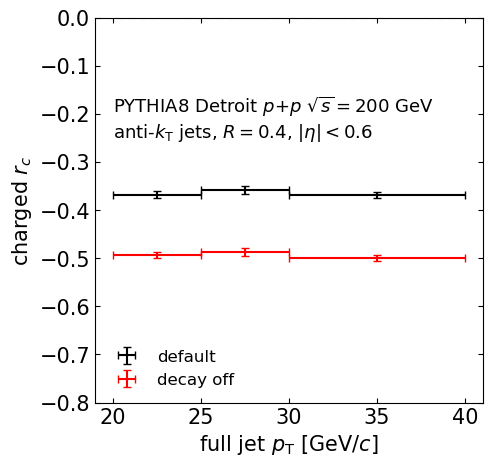

In [7]:
# fig12: charged rc vs pT
fig, ax = plt.subplots(figsize=(5, 5))
ax.errorbar(PT_CENTERS, rc_pt, xerr=PT_XERR, yerr=err_pt,
            capsize=3, ls='none', label='default', color='k')
ax.errorbar(PT_CENTERS, nodecay_rc_pt, xerr=PT_XERR, yerr=nodecay_err_pt,
            capsize=3, ls='none', label='decay off', color='r')
ax.axhline(0.0, color='grey', linestyle='--')
ax.set_xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
ax.set_ylabel('charged $r_c$', fontsize=15)
ax.set_ylim(-0.8, 0)
ax.text(20, -0.25,
        'PYTHIA8 Detroit $p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_\\mathrm{T}$ jets, $R=0.4$, $|\\eta|<0.6$',
        fontsize=13)
ax.legend(fontsize=12, loc='lower left', frameon=False)
ax.set_xticks(np.arange(20, 45, 5))
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
# plt.savefig('fig12.png', bbox_inches='tight')
# plt.savefig('fig12.pdf', bbox_inches='tight')
plt.show()

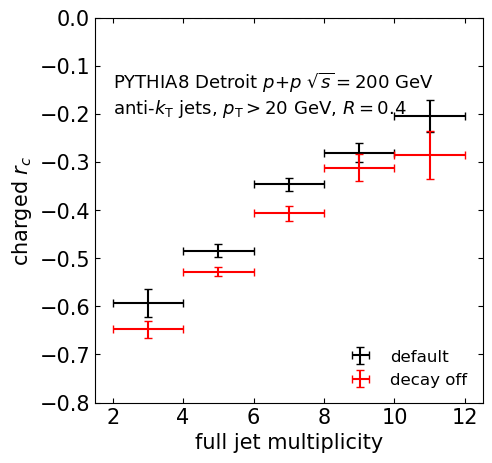

In [8]:
# fig13: charged rc vs multiplicity
fig, ax = plt.subplots(figsize=(5, 5))
ax.errorbar(N_CENTERS, rc_n, xerr=1, yerr=err_n,
            capsize=3, ls='none', label='default', color='k')
ax.errorbar(N_CENTERS, nodecay_rc_n, xerr=1, yerr=nodecay_err_n,
            capsize=3, ls='none', label='decay off', color='r')
ax.axhline(0.0, color='grey', linestyle='--')
ax.set_xlabel(r'full jet multiplicity', fontsize=15)
ax.set_ylabel('charged $r_c$', fontsize=15)
ax.set_ylim(-0.8, 0)
ax.text(2, -0.2,
        'PYTHIA8 Detroit $p$+$p$ $\\sqrt{s}=200$ GeV\n'
        r'anti-$k_\mathrm{T}$ jets, $p_{\mathrm{T}}>20$ GeV, $R=0.4$',
        fontsize=13)
ax.legend(fontsize=12, loc='lower right', frameon=False)
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
plt.savefig('fig13.png', bbox_inches='tight')
plt.savefig('fig13.pdf', bbox_inches='tight')
plt.show()

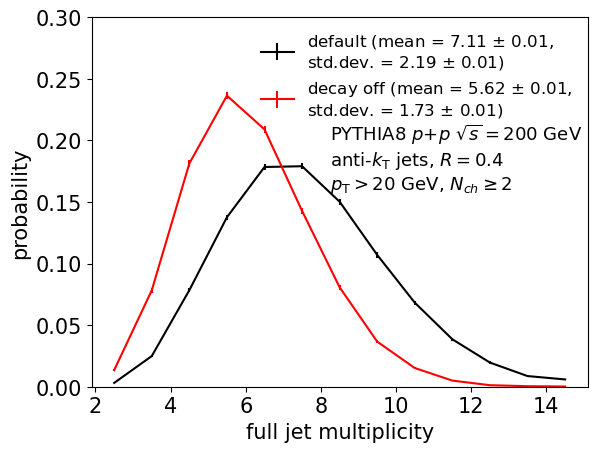

In [11]:
# fig14: multiplicity distribution
fig, ax = plt.subplots()
ax.errorbar(np.arange(2.5, 15.5), y, yerr=yerr, color='k',
            label='default (mean = 7.11 $\\pm$ 0.01,\nstd.dev. = 2.19 $\\pm$ 0.01)')
ax.errorbar(np.arange(2.5, 15.5), y_nodecay, yerr=yerr_nodecay, color='r',
            label='decay off (mean = 5.62 $\\pm$ 0.01,\nstd.dev. = 1.73 $\\pm$ 0.01)')
ax.set_xlabel(r'full jet multiplicity', fontsize=15)
ax.set_ylabel('probability', fontsize=15)
ax.set_ylim(0, 0.3)
ax.text(8.25, 0.16,
        'PYTHIA8 $p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_\\mathrm{T}$ jets, $R=0.4$\n'
        r'$p_{\mathrm{T}}>20$ GeV, $N_{ch}\geq2$',
        fontsize=13)
ax.legend(fontsize=12, loc='upper right', frameon=False)
plt.savefig('fig14.png', bbox_inches='tight')
plt.savefig('fig14.pdf', bbox_inches='tight')
plt.show()